<a href="https://colab.research.google.com/github/dhyun16/ESAA/blob/main/YB3%EC%A1%B0_project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [ ]:
sns.heatmap(data = train.corr(), annot=True, fmt = '.2f', linewidths=.5)

In [ ]:
sns.heatmap(data = test.corr(), annot=True, fmt = '.2f', linewidths=.5)

In [ ]:
for i in range(1,13):
    plt.subplot(3,4,i)
    sns.distplot(train.iloc[:,i])
plt.tight_layout()
plt.show()

In [ ]:
for i in range(1,12):
    plt.subplot(3,4,i)
    sns.distplot(test.iloc[:,i])
plt.tight_layout()
plt.show()

# **결정트리**

### **중복제거: 0.598**

In [ ]:
import pandas as pd

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
train = train.drop(columns=['index'])
test = test.drop(columns=['index'])

In [ ]:
# ==========================================
# 학습용 전처리(중복 데이터 제거)
# ==========================================

from sklearn.preprocessing import LabelEncoder

train_raw = pd.read_csv("train.csv")
test_raw = pd.read_csv("test.csv")
train = train_raw.copy()
test = test_raw.copy()

# 중복 제거
print("중복 제거 전 크기:", train.shape)

train = train.drop_duplicates()

print("중복 제거 후 크기:", train.shape)

# Wine Type 인코딩
train['type'] = train['type'].map({
    'red': 1,
    'white': 0
})

test['type'] = test['type'].map({
    'red': 1,
    'white': 0
})

# 파생변수 생성
train['bound_sulfur_dioxide'] = (
    train['total sulfur dioxide']
    - train['free sulfur dioxide']
)

test['bound_sulfur_dioxide'] = (
    test['total sulfur dioxide']
    - test['free sulfur dioxide']
)

# 기존 변수 삭제
train = train.drop(
    columns=['total sulfur dioxide']
)

test = test.drop(
    columns=['total sulfur dioxide']
)

# Quality Label Encoding
le = LabelEncoder()

train['quality'] = le.fit_transform(
    train['quality']
)

# X, y 분리
X = train.drop(columns=['quality'])
y = train['quality']

# Test 컬럼 정렬
X_test = test[X.columns]

print("\n[ 전처리 완료 ]")
print("X:", X.shape)
print("y:", y.shape)
print("X_test:", X_test.shape)

print("\n[ Quality Encoding ]")
print(dict(enumerate(le.classes_)))

중복 제거 전 크기: (5497, 14)
중복 제거 후 크기: (5497, 14)

[ 전처리 완료 ]
X: (5497, 13)
y: (5497,)
X_test: (1000, 13)

[ Quality Encoding ]
{0: np.int64(3), 1: np.int64(4), 2: np.int64(5), 3: np.int64(6), 4: np.int64(7), 5: np.int64(8), 6: np.int64(9)}


[ 결정트리 하이퍼파라미터 최적화 시작 ]
Fitting 5 folds for each of 336 candidates, totalling 1680 fits

[ 최적 하이퍼파라미터 ]
{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2}

[ 최적 교차검증 성능 ]
Best Macro F1: 0.3332
Best Accuracy: 0.5430

[ OOF 예측 및 상세 성능 평가 ]

OOF Accuracy : 0.5430
OOF Macro F1 : 0.3369

[ Classification Report ]
              precision    recall  f1-score   support

           0       0.03      0.04      0.03        26
           1       0.17      0.18      0.17       186
           2       0.59      0.61      0.60      1788
           3       0.59      0.55      0.57      2416
           4       0.47      0.50      0.49       924
           5       0.31      0.36      0.34       152
           6       0.12      0.20      0.15         5

    accuracy                           0.54      5497
   macro avg       0.33      0.35      0.34      5497
weighted avg       0.55      0.54      0.54      5497



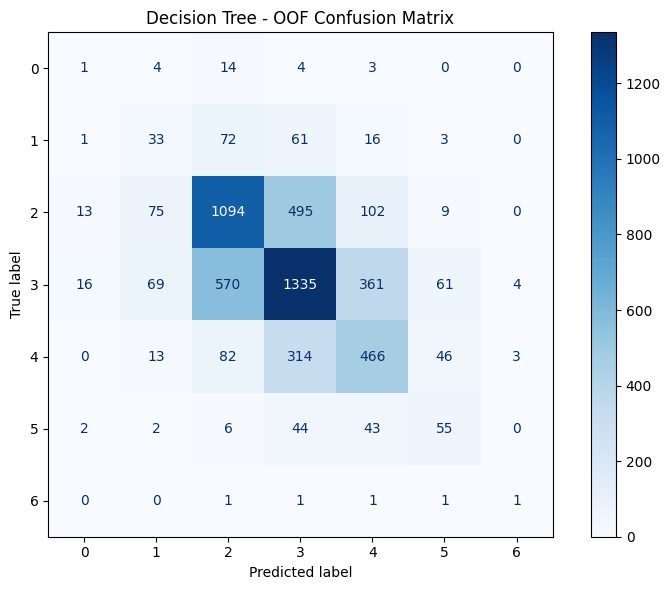


[ Feature Importance ]
             Feature  Importance
       fixed acidity    0.139443
             density    0.129014
                  pH    0.110660
 free sulfur dioxide    0.107922
             alcohol    0.103807
    volatile acidity    0.085952
bound_sulfur_dioxide    0.070267
           sulphates    0.056918
           chlorides    0.054262
      residual sugar    0.049311
         citric acid    0.048020
               index    0.043889
                type    0.000535


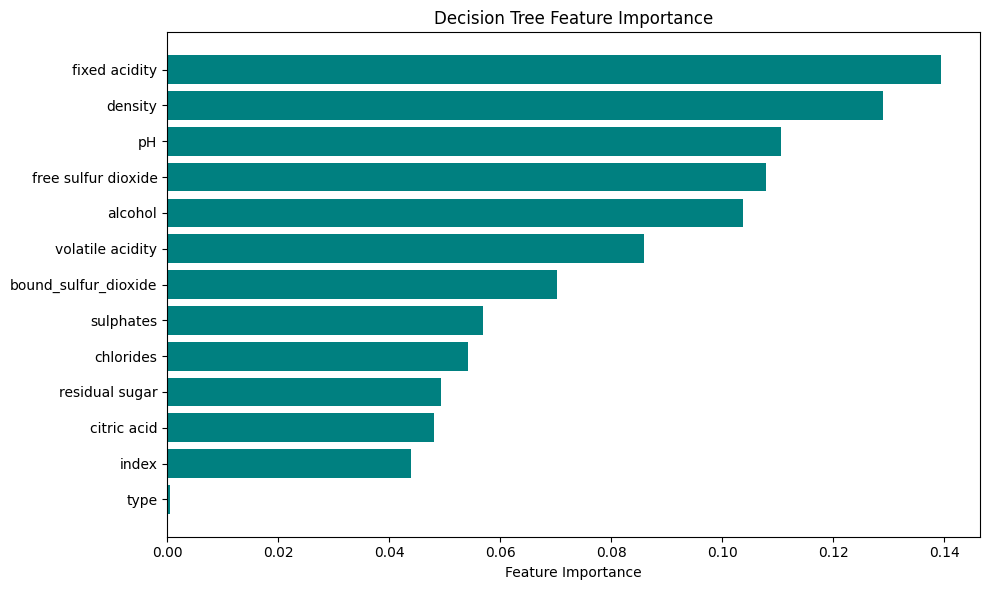


[ 최종 테스트 데이터 예측 ]

[ 제출 파일 생성 완료 ]
 index  quality
     0        5
     1        6
     2        5
     3        5
     4        8
     5        5
     6        5
     7        6
     8        6
     9        7

제출 데이터 크기: (1000, 2)
제출 파일: submission_final_dup_removed_final.csv

🎉 결정트리 학습 및 제출 파일 생성 완료!


In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_val_predict
)
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ==========================================
# 0. 재현성 확보
# ==========================================
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# ==========================================
# 1. 하이퍼파라미터 탐색 범위 설정
# ==========================================
param_grid = {
    'max_depth': [None, 3, 5, 7, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4, 8],
    'criterion': ['gini', 'entropy'],
    'class_weight': [None, 'balanced']
}

# ==========================================
# 2. GridSearchCV를 통한 최적 모델 탐색
# ==========================================
print("=" * 60)
print("[ 결정트리 하이퍼파라미터 최적화 시작 ]")
print("=" * 60)

dt = DecisionTreeClassifier(
    random_state=SEED
)

grid_search = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=skf,
    scoring={
        'accuracy': 'accuracy',
        'macro_f1': 'f1_macro'
    },
    refit='macro_f1',
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

grid_search.fit(X, y)

# 최적 모델
best_model = grid_search.best_estimator_

print("\n[ 최적 하이퍼파라미터 ]")
print(grid_search.best_params_)

print("\n[ 최적 교차검증 성능 ]")
print(f"Best Macro F1: {grid_search.best_score_:.4f}")

# 최적 파라미터 조합의 Accuracy도 확인
best_idx = grid_search.best_index_

print(
    f"Best Accuracy: "
    f"{grid_search.cv_results_['mean_test_accuracy'][best_idx]:.4f}"
)

# ==========================================
# 3. OOF 예측 및 상세 성능 평가
# ==========================================
print("\n" + "=" * 60)
print("[ OOF 예측 및 상세 성능 평가 ]")
print("=" * 60)

oof_pred = cross_val_predict(
    best_model,
    X,
    y,
    cv=skf,
    n_jobs=-1,
    method='predict'
)

oof_acc = accuracy_score(y, oof_pred)
oof_f1 = f1_score(y, oof_pred, average='macro')

print(f"\nOOF Accuracy : {oof_acc:.4f}")
print(f"OOF Macro F1 : {oof_f1:.4f}")

print("\n[ Classification Report ]")

print(
    classification_report(
        y,
        oof_pred,
        zero_division=0
    )
)

# ==========================================
# 4. Confusion Matrix 시각화
# ==========================================
cm = confusion_matrix(y, oof_pred)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(
    cmap=plt.cm.Blues,
    values_format='d',
    ax=ax
)

plt.title("Decision Tree - OOF Confusion Matrix")
plt.tight_layout()
plt.show()

# ==========================================
# 5. Feature Importance 시각화
# ==========================================
importances = best_model.feature_importances_

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
)

print("\n[ Feature Importance ]")
print(importance_df.to_string(index=False))

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df['Feature'],
    importance_df['Importance'],
    color='teal'
)

plt.gca().invert_yaxis()

plt.xlabel("Feature Importance")
plt.title("Decision Tree Feature Importance")
plt.tight_layout()
plt.show()

# ==========================================
# 6. 최종 모델 학습 완료 및 테스트 예측
# ==========================================
print("\n" + "=" * 60)
print("[ 최종 테스트 데이터 예측 ]")
print("=" * 60)

test_pred_encoded = best_model.predict(X_test)

# LabelEncoder 역변환
test_pred = le.inverse_transform(
    test_pred_encoded.astype(int)
)

# ==========================================
# 7. 제출 파일 생성 (index, quality 두 컬럼)
# ==========================================
submission = pd.DataFrame({
    'index': np.arange(len(test_pred)),
    'quality': test_pred
})

submission.to_csv(
    'submission_final_dup_removed_final.csv',
    index=False
)

print("\n[ 제출 파일 생성 완료 ]")
print(submission.head(10).to_string(index=False))

print("\n제출 데이터 크기:", submission.shape)
print("제출 파일: submission_final_dup_removed_final.csv")

print("\n🎉 결정트리 학습 및 제출 파일 생성 완료!")

### **중복 유지: 0.62**

In [ ]:
# ==========================================
# 학습용 전처리 (중복 데이터 유지)
# ==========================================

from sklearn.preprocessing import LabelEncoder

train = train_raw.copy()
test = test_raw.copy()

# Wine Type 인코딩
train['type'] = train['type'].map({
    'red': 1,
    'white': 0
})

test['type'] = test['type'].map({
    'red': 1,
    'white': 0
})

# 파생변수 생성
train['bound_sulfur_dioxide'] = (
    train['total sulfur dioxide']
    - train['free sulfur dioxide']
)

test['bound_sulfur_dioxide'] = (
    test['total sulfur dioxide']
    - test['free sulfur dioxide']
)

# 기존 변수 삭제
train = train.drop(
    columns=['total sulfur dioxide']
)

test = test.drop(
    columns=['total sulfur dioxide']
)

# Quality Label Encoding
le = LabelEncoder()

train['quality'] = le.fit_transform(
    train['quality']
)

# X, y 분리
X = train.drop(columns=['quality'])
y = train['quality']

# Test 컬럼 정렬
X_test = test[X.columns]

print("\n[ 전처리 완료 ]")
print("X:", X.shape)
print("y:", y.shape)
print("X_test:", X_test.shape)

print("\n[ Quality Encoding ]")
print(dict(enumerate(le.classes_)))


[ 전처리 완료 ]
X: (5497, 12)
y: (5497,)
X_test: (1000, 12)

[ Quality Encoding ]
{0: np.int64(3), 1: np.int64(4), 2: np.int64(5), 3: np.int64(6), 4: np.int64(7), 5: np.int64(8), 6: np.int64(9)}


[ 결정트리 하이퍼파라미터 최적화 시작 ]
Fitting 5 folds for each of 336 candidates, totalling 1680 fits

[ 최적 하이퍼파라미터 ]
{'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2}

[ 최적 교차검증 성능 ]
Best Macro F1: 0.2628
Best Accuracy: 0.4540

[ OOF 예측 및 상세 성능 평가 ]

OOF Accuracy : 0.4540
OOF Macro F1 : 0.2636

[ Classification Report ]
              precision    recall  f1-score   support

           0       0.05      0.04      0.04        26
           1       0.19      0.18      0.18       179
           2       0.52      0.51      0.51      1519
           3       0.51      0.49      0.50      2037
           4       0.35      0.37      0.36       754
           5       0.04      0.05      0.04       119
           6       0.20      0.20      0.20         5

    accuracy                           0.45      4639
   macro avg       0.26      0.26      0.26      4639
weighted avg       0.46      0.45      0.46      4639



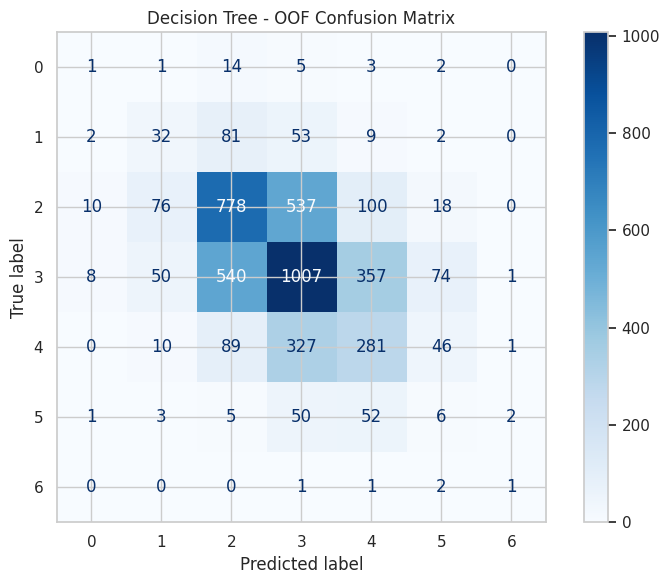


[ Feature Importance ]
             Feature  Importance
           chlorides    0.164311
 free sulfur dioxide    0.138072
             alcohol    0.107097
    volatile acidity    0.095312
       fixed acidity    0.087917
                  pH    0.084983
         citric acid    0.080748
      residual sugar    0.063518
bound_sulfur_dioxide    0.059065
             density    0.058620
           sulphates    0.056564
                type    0.003792


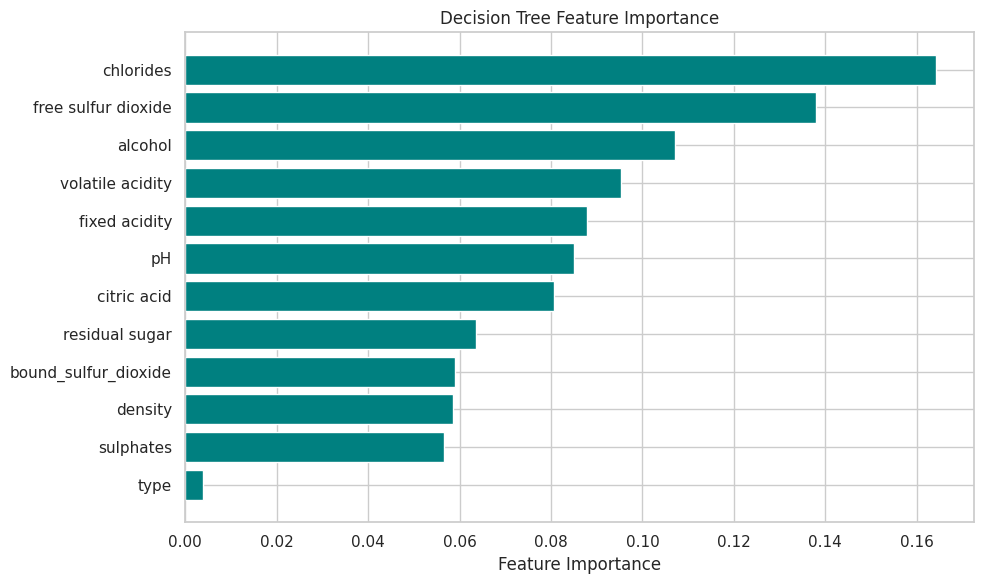


[ 최종 테스트 데이터 예측 ]

[ 제출 파일 생성 완료 ]
 index  quality
     0        6
     1        4
     2        6
     3        5
     4        7
     5        5
     6        7
     7        6
     8        6
     9        7

제출 데이터 크기: (1000, 2)
제출 파일: submission_final_dup_keep_final.csv

🎉 결정트리 학습 및 제출 파일 생성 완료!


In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_val_predict
)
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ==========================================
# 0. 재현성 확보
# ==========================================
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# ==========================================
# 1. 하이퍼파라미터 탐색 범위 설정
# ==========================================
param_grid = {
    'max_depth': [None, 3, 5, 7, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4, 8],
    'criterion': ['gini', 'entropy'],
    'class_weight': [None, 'balanced']
}

# ==========================================
# 2. GridSearchCV를 통한 최적 모델 탐색
# ==========================================
print("=" * 60)
print("[ 결정트리 하이퍼파라미터 최적화 시작 ]")
print("=" * 60)

dt = DecisionTreeClassifier(
    random_state=SEED
)

grid_search = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=skf,
    scoring={
        'accuracy': 'accuracy',
        'macro_f1': 'f1_macro'
    },
    refit='macro_f1',
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

grid_search.fit(X, y)

# 최적 모델
best_model = grid_search.best_estimator_

print("\n[ 최적 하이퍼파라미터 ]")
print(grid_search.best_params_)

print("\n[ 최적 교차검증 성능 ]")
print(f"Best Macro F1: {grid_search.best_score_:.4f}")

# 최적 파라미터 조합의 Accuracy도 확인
best_idx = grid_search.best_index_

print(
    f"Best Accuracy: "
    f"{grid_search.cv_results_['mean_test_accuracy'][best_idx]:.4f}"
)

# ==========================================
# 3. OOF 예측 및 상세 성능 평가
# ==========================================
print("\n" + "=" * 60)
print("[ OOF 예측 및 상세 성능 평가 ]")
print("=" * 60)

oof_pred = cross_val_predict(
    best_model,
    X,
    y,
    cv=skf,
    n_jobs=-1,
    method='predict'
)

oof_acc = accuracy_score(y, oof_pred)
oof_f1 = f1_score(y, oof_pred, average='macro')

print(f"\nOOF Accuracy : {oof_acc:.4f}")
print(f"OOF Macro F1 : {oof_f1:.4f}")

print("\n[ Classification Report ]")

print(
    classification_report(
        y,
        oof_pred,
        zero_division=0
    )
)

# ==========================================
# 4. Confusion Matrix 시각화
# ==========================================
cm = confusion_matrix(y, oof_pred)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(
    cmap=plt.cm.Blues,
    values_format='d',
    ax=ax
)

plt.title("Decision Tree - OOF Confusion Matrix")
plt.tight_layout()
plt.show()

# ==========================================
# 5. Feature Importance 시각화
# ==========================================
importances = best_model.feature_importances_

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
)

print("\n[ Feature Importance ]")
print(importance_df.to_string(index=False))

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df['Feature'],
    importance_df['Importance'],
    color='teal'
)

plt.gca().invert_yaxis()

plt.xlabel("Feature Importance")
plt.title("Decision Tree Feature Importance")
plt.tight_layout()
plt.show()

# ==========================================
# 6. 최종 모델 학습 완료 및 테스트 예측
# ==========================================
print("\n" + "=" * 60)
print("[ 최종 테스트 데이터 예측 ]")
print("=" * 60)

# GridSearchCV의 refit=True에 의해
# best_model은 이미 전체 X, y로 재학습된 상태

test_pred_encoded = best_model.predict(X_test)

# LabelEncoder 역변환
test_pred = le.inverse_transform(
    test_pred_encoded.astype(int)
)

# ==========================================
# 7. 제출 파일 생성
# ==========================================
submission = pd.DataFrame({
    'index': np.arange(len(test_pred)),
    'quality': test_pred
})

submission.to_csv(
    'submission_final_dup_keep.csv',
    index=False
)

print("\n[ 제출 파일 생성 완료 ]")
print(submission.head(10).to_string(index=False))

print("\n제출 데이터 크기:", submission.shape)
print("제출 파일: submission_final_dup_keep.csv")

print("\n🎉 결정트리 학습 및 제출 파일 생성 완료!")

# **RandomForest**

 ### **중복 유지 (0.695)**

In [ ]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

train['type'] = train['type'].map({'white': 1, 'red': 0})
test['type'] = test['type'].map({'white': 1, 'red': 0})

In [ ]:
# train 데이터 준비 (quality 분리)
train['bound sulfur dioxide'] = train['total sulfur dioxide'] - train['free sulfur dioxide']
test['bound sulfur dioxide'] = test['total sulfur dioxide'] - test['free sulfur dioxide']

X_train = train.drop(columns=['index', 'quality', 'total sulfur dioxide'])
y_train = train['quality']

X_test = test.drop(columns=['index', 'total sulfur dioxide'])

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# 하이퍼파라미터
param_grid00_2 = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'class_weight': [None, 'balanced']
    }

rf = RandomForestClassifier(random_state=42)
grid00_2 = GridSearchCV(rf, param_grid00_2, cv=5, scoring='accuracy', n_jobs=-1)
grid00_2.fit(X_train, y_train)

pred00_2 = grid00_2.predict(X_test)

submission00_2 = pd.read_csv('sample_submission.csv')
submission00_2['quality'] = pred00_2
submission00_2.to_csv('pred00_2.csv',index = False)

### **중복 제거(0.686)**

In [ ]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

train['type'] = train['type'].map({'white': 1, 'red': 0})
test['type'] = test['type'].map({'white': 1, 'red': 0})

train['bound sulfur dioxide'] = train['total sulfur dioxide'] - train['free sulfur dioxide']
test['bound sulfur dioxide'] = test['total sulfur dioxide'] - test['free sulfur dioxide']

In [ ]:
train_dedup = train.drop(columns=['index']).drop_duplicates()

In [ ]:
X_train_d = train_dedup.drop(columns=['quality', 'total sulfur dioxide'])
y_train_d = train_dedup['quality']

# test 데이터 준비 (test는 index만 제거)
X_test = test.drop(columns=['index', 'total sulfur dioxide'])

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

param_grid12_2 = {
    'n_estimators': [500, 600, 700],
    'max_depth': [15, 20, None],
    'min_samples_split': [2, 3, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', None]
}

rf = RandomForestClassifier(random_state=42)

grid12_2 = GridSearchCV(rf, param_grid12_2, cv=5, scoring='accuracy', n_jobs=-1,verbose=1)
grid12_2.fit(X_train_d, y_train_d)

print("Best accuracy CV Score:", grid12_2.best_score_)
print("Best Params:", grid12_2.best_params_)

# 예측 및 제출 파일 생성
pred12_2 = grid12_2.predict(X_test)

submission12_2 = pd.read_csv('sample_submission.csv')
submission12_2['quality'] = pred12_2
submission12_2.to_csv('pred12_2.csv', index=False)

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best accuracy CV Score: 0.5774939087899416
Best Params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 500}


Best Params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 600}

# **XGBoost**

### **중복제거: 0.668점**

In [ ]:
!pip install xgboost

import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV

# 1. 데이터 불러오기
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')


# 2. 데이터 전처리

# Index 제거
train = train.drop(columns=['index'])
test = test.drop(columns=['index'])

# Wine type 인코딩 (red = 0, white = 1)
train['type'] = train['type'].map({'red': 0, 'white': 1})
test['type'] = test['type'].map({'red': 0, 'white': 1})

# 결합 이산화황 변수 생성
train['bound sulfur dioxide'] = (
    train['total sulfur dioxide'] - train['free sulfur dioxide']
)
test['bound sulfur dioxide'] = (
    test['total sulfur dioxide'] - test['free sulfur dioxide']
)

# Total sulfur dioxide 제거 (Free sulfur dioxide 유지)
train = train.drop(columns=['total sulfur dioxide'])
test = test.drop(columns=['total sulfur dioxide'])

# Train 데이터 중복 제거
train = train.drop_duplicates().reset_index(drop=True)

# 3. 독립변수와 종속변수 분리
X = train.drop(columns=['quality'])
y = train['quality']

# Test 데이터 변수 구성 및 순서 통일
X_test = test[X.columns]


# 4. Quality Label Encoding
le = LabelEncoder()
y_encoded = le.fit_transform(y)# 5. 교차검증 설정
SEED = 42

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)


# 6. XGBoost 모델 설정
xgb_model = XGBClassifier(
    objective='multi:softprob',
    num_class=len(le.classes_),
    eval_metric='mlogloss',
    random_state=SEED,
    n_jobs=1,
    tree_method='hist'
)

# 7. 하이퍼파라미터 탐색 범위
param_dist = {
    'n_estimators': [200, 300, 400, 500, 600],
    'max_depth': [3, 4, 5, 6, 7],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'min_child_weight': [1, 3, 5],
    'gamma': [0, 0.1, 0.2],
    'reg_lambda': [1, 3, 5]
}

In [ ]:
# 8. RandomizedSearchCV 실행
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_dist,
    n_iter=20,
    scoring='accuracy',
    cv=cv,
    random_state=SEED,
    n_jobs=-1,
    verbose=1,
    refit=True
)

random_search.fit(X, y_encoded)

In [ ]:
# 9. 최적 모델 및 성능 확인
best_xgb = random_search.best_estimator_

print("최적 하이퍼파라미터:")
print(random_search.best_params_)

print("\n최고 교차검증 Accuracy:")
print(round(random_search.best_score_, 4))


In [ ]:
# 10. Feature Importance 시각화
importance = pd.Series(
    best_xgb.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(8, 6))
importance.plot(kind='barh')
plt.title('Optimized XGBoost Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


In [ ]:
# 11. Test 데이터 예측


# 최적 모델로 Test 데이터 예측
pred = best_xgb.predict(X_test)

# Label Encoding 이전의 원래 Quality 값으로 복원
pred_quality = le.inverse_transform(pred.astype(int))

In [ ]:
# 12. 제출 파일 생성 및 다운로드

# Sample submission 불러오기
submission = pd.read_csv('sample_submission.csv')

# 예측 결과 입력
submission['quality'] = pred_quality

# 예측값 개수 확인
assert len(submission) == len(test)

# CSV 파일 저장
submission.to_csv('xgboost_remove.csv', index=False)

# 파일 다운로드
from google.colab import files
files.download('xgboost_remove.csv')

### **중복유지: 0.688점**

In [ ]:
!pip install xgboost

import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV


# 1. 데이터 불러오기
train = pd.read_csv('train.csv')

test = pd.read_csv('test.csv')


# 2. 데이터 전처리

# Index 제거
train = train.drop(columns=['index'])
test = test.drop(columns=['index'])

# Wine type 인코딩 (red = 0, white = 1)
train['type'] = train['type'].map({'red': 0, 'white': 1})
test['type'] = test['type'].map({'red': 0, 'white': 1})

# 결합 이산화황 변수 생성
train['bound sulfur dioxide'] = (
    train['total sulfur dioxide'] - train['free sulfur dioxide']
)

test['bound sulfur dioxide'] = (
    test['total sulfur dioxide'] - test['free sulfur dioxide']
)

# Total sulfur dioxide 제거 (Free sulfur dioxide 유지)
train = train.drop(columns=['total sulfur dioxide'])
test = test.drop(columns=['total sulfur dioxide'])


# 3. 독립변수와 종속변수 분리
X = train.drop(columns=['quality'])
y = train['quality']

# Test 데이터 변수 구성 및 순서 통일
X_test = test[X.columns]


# 4. Quality Label Encoding
le = LabelEncoder()
y_encoded = le.fit_transform(y)


# 5. 교차검증 설정
SEED = 42

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)


# 6. XGBoost 모델 설정
xgb_model = XGBClassifier(
    objective='multi:softprob',
    num_class=len(le.classes_),
    eval_metric='mlogloss',
    random_state=SEED,
    n_jobs=1,
    tree_method='hist'
)


# 7. 하이퍼파라미터 탐색 범위
param_dist = {
    'n_estimators': [200, 300, 400, 500, 600],
    'max_depth': [3, 4, 5, 6, 7],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'min_child_weight': [1, 3, 5],
    'gamma': [0, 0.1, 0.2],
    'reg_lambda': [1, 3, 5]
}

In [ ]:
# 8. RandomizedSearchCV 실행
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_dist,
    n_iter=20,
    scoring='accuracy',
    cv=cv,
    random_state=SEED,
    n_jobs=-1,
    verbose=1,
    refit=True
)

random_search.fit(X, y_encoded)

In [ ]:
# 9. 최적 모델 및 성능 확인
best_xgb = random_search.best_estimator_

print("최적 하이퍼파라미터:")
print(random_search.best_params_)

print("\n최고 교차검증 Accuracy:")
print(round(random_search.best_score_, 4))

In [ ]:
# 10. Feature Importance 시각화
importance = pd.Series(
    best_xgb.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(8, 6))
importance.plot(kind='barh')
plt.title('Optimized XGBoost Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [ ]:
# 11. Test 데이터 예측
pred = best_xgb.predict(X_test)

# Label Encoding 이전의 원래 Quality 값으로 복원
pred_quality = le.inverse_transform(pred.astype(int))

In [ ]:
# 12. 제출 파일 생성 및 다운로드
submission = pd.read_csv(
    'sample_submission.csv'
)

submission['quality'] = pred_quality

assert len(submission) == len(test)

submission.to_csv('xgboost_optimized_keep.csv', index=False)

from google.colab import files
files.download('xgboost_optimized_keep.csv')

# **로지스틱**

**0.69**

In [ ]:
## 데이터 불러오기
import warnings
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
submission = pd.read_csv('sample_submission.csv')

print('train:', train.shape, '| test:', test.shape, '| 제출 양식:', submission.shape)
print('결측치:', train.isna().sum().sum(), test.isna().sum().sum())
print(train['type'].value_counts())

## 중복 제거
train = train.drop(columns='index')
test = test.drop(columns='index')

print('중복 제거 전:', train.shape)
print('완전 중복 행 수:', train.duplicated().sum())
train = train.drop_duplicates().reset_index(drop=True)
print('중복 제거 후:', train.shape)

In [ ]:
## 새 변수 만들기(유리이산화황비율,결합이산화황,당알코올비율,총산도(고정산도+휘발성산도))
for data in (train, test):
    data['free_so2_ratio'] = data['free sulfur dioxide'] / data['total sulfur dioxide']
    data['bound sulfur dioxide'] = data['total sulfur dioxide'] - data['free sulfur dioxide']
    data['sugar_alcohol'] = data['residual sugar'] / data['alcohol']
    data['total_acidity'] = data['fixed acidity'] + data['volatile acidity']

new_cols = ['free_so2_ratio', 'bound sulfur dioxide', 'sugar_alcohol', 'total_acidity']
print(train[new_cols].describe().round(3).T[['mean', 'min', 'max']])
print(train[new_cols + ['quality']].corr(method='spearman')['quality'].round(3))

In [ ]:
## 왜도 확인(로그변환이 좋을지 제곱근 변환이 좋을지 확인)
features = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
            'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
            'pH', 'sulphates', 'alcohol',
            'free_so2_ratio', 'bound sulfur dioxide', 'sugar_alcohol', 'total_acidity']

skew = pd.DataFrame({'원래': train[features].skew(),
                     '로그': np.log(train[features].clip(lower=1e-9)).skew(),
                     '제곱근': np.sqrt(train[features]).skew()})
print(skew.round(2))

## 로그 제곱근 변환
log_cols = ['fixed acidity', 'volatile acidity', 'residual sugar', 'chlorides',
            'sulphates', 'sugar_alcohol', 'total_acidity']
sqrt_cols = ['free sulfur dioxide']

for data in (train, test):
    data[log_cols] = np.log(data[log_cols])
    data[sqrt_cols] = np.sqrt(data[sqrt_cols])

print(train[log_cols + sqrt_cols].skew().round(2))

In [ ]:
## 레드 화이트 나누기
red_train = train[train['type'] == 'red']
white_train = train[train['type'] == 'white']
red_test = test[test['type'] == 'red']
white_test = test[test['type'] == 'white']

print('train 레드:', red_train.shape, '| train 화이트:', white_train.shape)
print('test 레드:', red_test.shape, '| test 화이트:', white_test.shape)
print(pd.crosstab(train['quality'], train['type']))

In [ ]:
## 교차 검증 설정
from sklearn.model_selection import StratifiedKFold, GridSearchCV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## degree와 C찾기
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression

def make_features(X_train, X_test, degree):
    scaler1 = StandardScaler()
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    scaler2 = StandardScaler()
    train_feat = scaler2.fit_transform(poly.fit_transform(scaler1.fit_transform(X_train)))
    test_feat = scaler2.transform(poly.transform(scaler1.transform(X_test)))
    return train_feat, test_feat

params = {'C': [0.01, 0.03, 0.1, 1, 10]}
best = {}

for name, data in [('red', red_train), ('white', white_train)]:
    X = data[features]
    y = data['quality']
    results = []
    for degree in [1, 2]:
        X_feat, _ = make_features(X, X, degree)
        grid = GridSearchCV(LogisticRegression(max_iter=20000), param_grid=params, cv=cv, scoring='accuracy')
        grid.fit(X_feat, y)
        print(f'{name} | degree {degree} | 최적 C: {grid.best_params_["C"]} | 최고 정확도: {grid.best_score_:.4f}')
        results.append({'degree': degree, 'C': grid.best_params_['C'], 'score': grid.best_score_})
    best[name] = max(results, key=lambda r: r['score'])
    print(f'{name} 최종 선택: degree {best[name]["degree"]}, C {best[name]["C"]}')

In [ ]:
## 학습/예측
pred = pd.Series(0, index=test.index)

for name, tr, te in [('red', red_train, red_test), ('white', white_train, white_test)]:
    X_feat, X_test_feat = make_features(tr[features], te[features], best[name]['degree'])
    model = LogisticRegression(C=best[name]['C'], max_iter=20000)
    model.fit(X_feat, tr['quality'])
    pred.loc[te.index] = model.predict(X_test_feat)

submission['quality'] = pred.values
submission.to_csv('submission_lr_final.csv', index=False)

print(submission.shape)
print(submission['quality'].value_counts().sort_index())

In [ ]:
## train데이터와 일치하는 test행 값은 같은 quality 로
raw_train = pd.read_csv('train.csv').drop(columns='index')
raw_test = pd.read_csv('test.csv').drop(columns='index')
key_cols = list(raw_test.columns)

lookup = raw_train.groupby(key_cols)['quality'].first()
key = pd.MultiIndex.from_frame(raw_test[key_cols])
matched = key.isin(lookup.index)

submission_match = submission.copy()
submission_match.loc[matched, 'quality'] = lookup.loc[key[matched]].values
submission_match.to_csv('submission_lr_final_match.csv', index=False)

print('train과 같은 test 행:', matched.sum())
print('보정으로 바뀐 행:', (submission_match['quality'] != submission['quality']).sum())
print(submission_match['quality'].value_counts().sort_index())

# **보팅**

### **중복 유지: 0.69**

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from xgboost import XGBClassifier

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

# 인코딩
train['type'] = train['type'].map({'white': 1, 'red': 0})
test['type'] = test['type'].map({'white': 1, 'red': 0})

# 변수 생성
train['bound sulfur dioxide'] = train['total sulfur dioxide'] - train['free sulfur dioxide']
test['bound sulfur dioxide'] = test['total sulfur dioxide'] - test['free sulfur dioxide']

# train 데이터 준비
X_train = train.drop(columns=['index', 'quality', 'total sulfur dioxide'])
y_train = train['quality']

# test 데이터 준비
X_test = test.drop(columns=['index', 'total sulfur dioxide'])

## XGBoost 및 보팅 학습을 위한 타겟 라벨 인코딩 (3~9 -> 0~6)
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)

## 각 모델의 최적 파라미터 적용
best_dt = DecisionTreeClassifier(
    class_weight='balanced',
    criterion='entropy',
    max_depth=20,
    min_samples_leaf=1,
    min_samples_split=2,
    random_state=42
)

best_rf = RandomForestClassifier(
    n_estimators=600,
    max_depth=None,
    max_features='sqrt',
    min_samples_leaf=1,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

best_xgb = XGBClassifier(
    objective='multi:softprob',
    num_class=7,
    n_estimators=600,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.8,
    min_child_weight=3,
    gamma=0,
    reg_lambda=1,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=1,
    tree_method='hist'
)

best_lr = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    LogisticRegression(C=0.01, max_iter=20000, random_state=42)
)

# 소프트 보팅 구성 및 교차검증 정확도 확인 (test 데이터에 정답 없어서 교차검증으로 정확도 확인)
vo_clf = VotingClassifier(
    estimators=[
        ('rf', best_rf),
        ('xgb', best_xgb),
        ('lr', best_lr),
        ('dt', best_dt)
    ],
    voting='soft',
    weights=[4, 3, 1, 1]
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 개별 모델 & 보팅 정확도 비교
classifiers = [
    ('RandomForest', best_rf),
    ('XGBoost', best_xgb),
    ('Logistic', best_lr),
    ('DecisionTree', best_dt),
    ('Voting', vo_clf)
]

for name, classifier in classifiers:
    scores = cross_val_score(classifier, X_train, y_train_enc, cv=skf, scoring='accuracy', n_jobs=-1)
    print(f'{name} 교차검증 정확도: {scores.mean():.4f}')

# 전체 학습 데이터로 학습 후 X_test 예측 및 원래 점수로 복원
vo_clf.fit(X_train, y_train_enc)
pred_vo = vo_clf.predict(X_test)
pred_quality = le.inverse_transform(pred_vo)  # 0~6 -> 3~9로 복원

# 제출 파일 저장
submission = pd.read_csv('sample_submission.csv')
submission['quality'] = pred_quality
submission.to_csv('submission_voting.csv', index=False)

### **중복 제거: 0.688**

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from xgboost import XGBClassifier

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

# 인코딩
train['type'] = train['type'].map({'white': 1, 'red': 0})
test['type'] = test['type'].map({'white': 1, 'red': 0})

# 변수 생성
train['bound sulfur dioxide'] = train['total sulfur dioxide'] - train['free sulfur dioxide']
test['bound sulfur dioxide'] = test['total sulfur dioxide'] - test['free sulfur dioxide']

# 중복 제거
train_dedup = train.drop(columns=['index']).drop_duplicates()

# train 데이터 준비
X_train_d = train_dedup.drop(columns=['quality', 'total sulfur dioxide'])
y_train_d = train_dedup['quality']

# test 데이터 준비
X_test = test.drop(columns=['index', 'total sulfur dioxide'])

## XGBoost 및 보팅 학습을 위한 타겟 라벨 인코딩 (3~9 -> 0~6)
le = LabelEncoder()
y_train_d_enc = le.fit_transform(y_train_d)

## 각 모델의 최적 파라미터 적용
best_dt = DecisionTreeClassifier(
    class_weight='balanced',
    criterion='entropy',
    max_depth=20,
    min_samples_leaf=1,
    min_samples_split=2,
    random_state=42
)

best_rf = RandomForestClassifier(
    n_estimators=600,
    max_depth=None,
    max_features='sqrt',
    min_samples_leaf=1,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

best_xgb = XGBClassifier(
    objective='multi:softprob',
    num_class=7,
    n_estimators=600,
    max_depth=7,
    learning_rate=0.01,
    subsample=0.8,
    colsample_bytree=0.7,
    min_child_weight=1,
    gamma=0,
    reg_lambda=1,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=1,
    tree_method='hist'
)

best_lr = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    LogisticRegression(C=0.01, max_iter=20000, random_state=42))

# 소프트 보팅 구성 및 교차검증 정확도 확인 (test 데이터에 정답 없어서 교차검증으로 정확도 확인)
vo_clf_d = VotingClassifier(
    estimators=[
        ('rf', best_rf),
        ('xgb', best_xgb),
        ('lr', best_lr),
        ('dt', best_dt)
    ],
    voting='soft',
    weights=[4, 3, 1, 1]
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 개별 모델 & 보팅 정확도 비교
classifiers_d = [
    ('RandomForest', best_rf),
    ('XGBoost', best_xgb),
    ('Logistic', best_lr),
    ('DecisionTree', best_dt),
    ('Voting', vo_clf_d)
]

for name, classifier_d in classifiers_d:
    scores = cross_val_score(classifier_d, X_train_d, y_train_d_enc, cv=skf, scoring='accuracy', n_jobs=-1)
    print(f'{name} 교차검증 정확도: {scores.mean():.4f}')

## 전체 학습 데이터로 학습 후 X_test 예측 및 원래 점수로 복원
vo_clf_d.fit(X_train_d, y_train_d_enc)
pred_vo_d = vo_clf_d.predict(X_test)
pred_quality_d = le.inverse_transform(pred_vo_d)  ## 0~6 -> 3~9로 복원

# 제출 파일 저장
submission = pd.read_csv('sample_submission.csv')
submission['quality'] = pred_quality_d
submission.to_csv('submission_voting_dedup.csv', index=False)

# **스태킹: 0.691**

In [ ]:
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 스태킹 데이터 생성 함수 정의 (다중 분류 확률 기반)
def get_stacking_base_datasets(model, X_train_n, y_train_n, X_test_n, n_folds):
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)
    num_classes = len(np.unique(y_train_n))

    # 다중 분류이므로 클래스 개수(7개)만큼 열 생성
    train_fold_pred = np.zeros((X_train_n.shape[0], num_classes))
    test_pred = np.zeros((X_test_n.shape[0], num_classes))

    for folder_counter, (train_index, valid_index) in enumerate(skf.split(X_train_n, y_train_n)):
        X_tr = X_train_n.iloc[train_index]
        y_tr = y_train_n[train_index]
        X_te = X_train_n.iloc[valid_index]

        model.fit(X_tr, y_tr)
        # 예측 확률(predict_proba)을 저장
        train_fold_pred[valid_index, :] = model.predict_proba(X_te)
        test_pred += model.predict_proba(X_test_n) / n_folds

    return train_fold_pred, test_pred

# 1. 기반 모델별 학습/테스트 메타 데이터 생성 (보팅의 4개 모델 활용)
rf_train, rf_test = get_stacking_base_datasets(best_rf, X_train, y_train_enc, X_test, 5)
xgb_train, xgb_test = get_stacking_base_datasets(best_xgb, X_train, y_train_enc, X_test, 5)
lr_train, lr_test = get_stacking_base_datasets(best_lr, X_train, y_train_enc, X_test, 5)
dt_train, dt_test = get_stacking_base_datasets(best_dt, X_train, y_train_enc, X_test, 5)

# 2. 데이터 결합
Stack_final_X_train = np.concatenate((rf_train, xgb_train, lr_train, dt_train), axis=1)
Stack_final_X_test = np.concatenate((rf_test, xgb_test, lr_test, dt_test), axis=1)

print('원본 학습 피처 데이터 Shape:', X_train.shape, '원본 테스트 피처 Shape:', X_test.shape)
print('스태킹 학습 피처 데이터 Shape:', Stack_final_X_train.shape, '스태킹 테스트 피처 데이터 Shape:', Stack_final_X_test.shape)

# 3. 최종 메타 모델 학습 및 예측
lr_final = LogisticRegression(max_iter=1000, random_state=42)
lr_final.fit(Stack_final_X_train, y_train_enc)

# 훈련 데이터 기준 스태킹 정확도 확인 (y_test가 없으므로 train으로 확인)
train_pred = lr_final.predict(Stack_final_X_train)
print(f'최종 메타 모델의 학습 정확도: {accuracy_score(y_train_enc, train_pred):.4f}')

# 테스트 데이터 예측 및 제출 파일 저장
stack_final = lr_final.predict(Stack_final_X_test)
submission = pd.read_csv('sample_submission.csv')
submission['quality'] = le.inverse_transform(stack_final)
submission.to_csv('submission_stacking_manual.csv', index=False)